In [1]:
import sys; sys.path.insert(0, "../src")
from ds_prep.stats_utils import two_prop_ztest

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm

## Part A

### A/A Testing

In [2]:
rng = np.random.default_rng(0)

x1s = rng.binomial(n=5000, p=0.12, size=1000)
x2s = rng.binomial(n=5000, p=0.12, size=1000)

results = []

for x1, x2 in zip(x1s, x2s):
    res = two_prop_ztest(x1, 5000, x2, 5000)
    results.append(res["p_value"])

pvals = np.array(results)
fpr = (pvals < 0.05).mean()
print(f"FPR: {fpr}")

FPR: 0.051


In [3]:
n_sims = len(pvals)
se = np.sqrt(fpr * (1 - fpr) / n_sims)
lo, hi = fpr - 1.96 * se, fpr + 1.96 * se
print(f"FPR = {fpr:.3f}, 95% CI ({lo:.3f}, {hi:.3f})")

FPR = 0.051, 95% CI (0.037, 0.065)


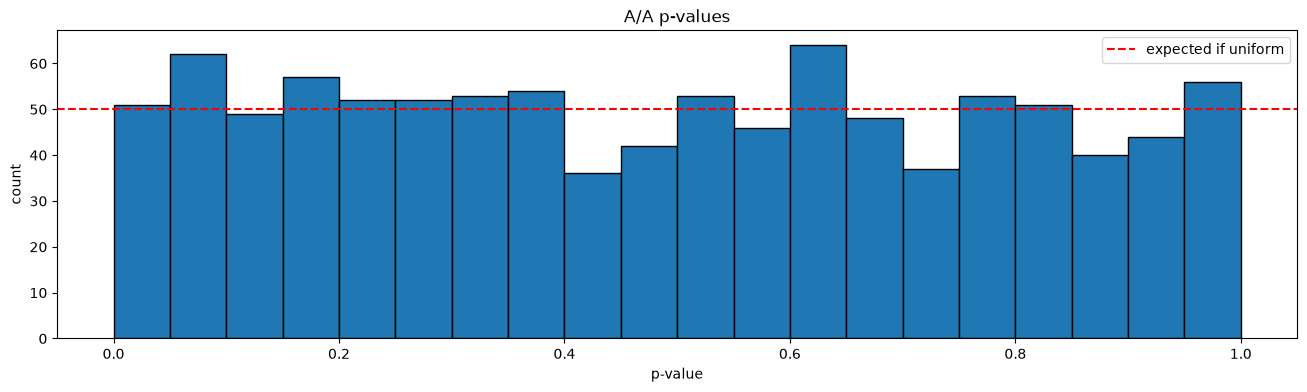

In [4]:
plt.figure(figsize=(16, 4))
plt.hist(pvals, bins=20, range=(0, 1), edgecolor="black")
plt.axhline(len(pvals) / 20, color="red", linestyle="--", label="expected if uniform")
plt.xlabel("p-value"); plt.ylabel("count"); plt.title("A/A p-values")
plt.legend()
plt.show()

### Realism Twist

In [5]:
df = pd.read_csv("../data/experiment.csv")
df.head()

,user_id,variant,exposure_date,pre_gmv_28d,orders_14d,gmv_14d
0,14357,treatment,2026-09-04,1534.52,4,1441.69
1,3440,control,2026-09-04,1817.86,1,368.36
2,12154,control,2026-09-01,0.00,1,421.78
3,15030,treatment,2026-09-06,0.00,1,258.44
4,18550,treatment,2026-09-01,518.17,1,166.94


In [6]:
control_df = df[df["variant"] == "control"].reset_index(drop = True).copy()
conv = (control_df["orders_14d"] > 0).to_numpy().astype(int)
n = len(conv)
half = n // 2

pvals_real = []
for _ in range(1000):
    perm = rng.permutation(n)
    a, b = conv[perm[:half]], conv[perm[half:]]      # numpy: integers select rows
    res = two_prop_ztest(a.sum(), len(a), b.sum(), len(b))
    pvals_real.append(res["p_value"])

pvals_real = np.array(pvals_real)
fpr_real = (pvals_real < 0.05).mean()
print(f"FPR Real: {fpr_real}")

FPR Real: 0.056


In [7]:
n_sims = len(pvals_real)
se = np.sqrt(fpr_real * (1 - fpr_real) / n_sims)
lo, hi = fpr_real - 1.96 * se, fpr_real + 1.96 * se
print(f"FPR = {fpr_real:.3f}, 95% CI ({lo:.3f}, {hi:.3f})")

FPR = 0.056, 95% CI (0.042, 0.070)


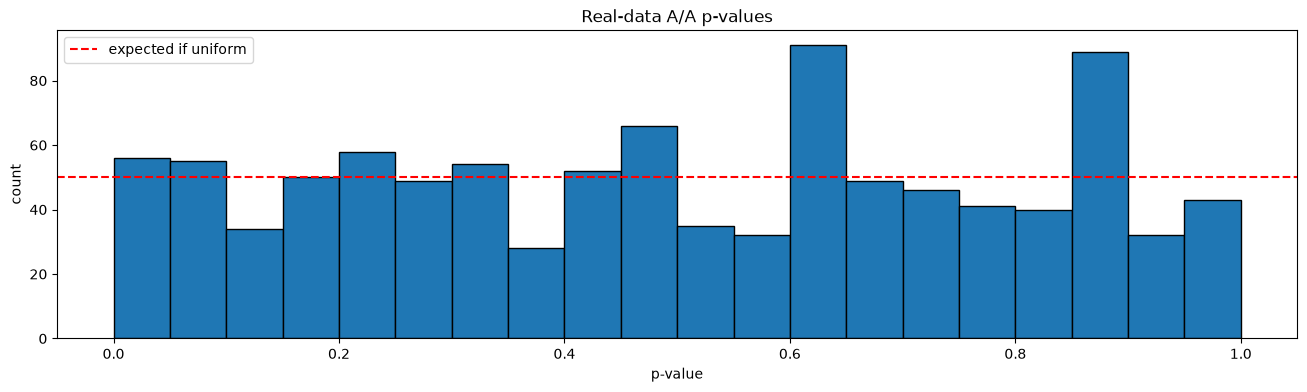

In [8]:
plt.figure(figsize=(16, 4))
plt.hist(pvals_real, bins=20, range=(0, 1), edgecolor="black")
plt.axhline(len(pvals_real) / 20, color="red", linestyle="--", label="expected if uniform")
plt.xlabel("p-value"); plt.ylabel("count"); plt.title("Real-data A/A p-values")
plt.legend()
plt.show()

### Part A Conclusion
“Across 1,000 simulated A/A tests, the false-positive rate was 5.1% (95% CI 3.7%–6.5%), consistent with α = 0.05, so the z-test is calibrated. The same held on reshuffled real control users (5.6%).”

## Part B

### Power

In [9]:
def analytic_power(n, p1=0.12, rel=0.05, alpha=0.05):
    p2 = p1 * (1 + rel)
    delta = p2 - p1
    se = np.sqrt(p1*(1-p1)/n + p2*(1-p2)/n)
    z = norm.ppf(1 - alpha/2)
    return norm.cdf(delta/se - z) + norm.cdf(-delta/se - z)

In [10]:
rng = np.random.default_rng(0)
rows = []

for n_per_arm in [5000, 15000, 30000, 45000, 48000]:

    x1s = rng.binomial(n=n_per_arm, p=0.120, size=1000)
    x2s = rng.binomial(n=n_per_arm, p=0.126, size=1000)

    results = []

    for x1, x2 in zip(x1s, x2s):
        res = two_prop_ztest(x1, n_per_arm, x2, n_per_arm)
        results.append(res["p_value"])

    pvals = np.array(results)
    ep = (pvals < 0.05).mean()
    ap = analytic_power(n_per_arm, p1 = 0.120, rel = 0.05)
    print(f"Users per arm: {n_per_arm}, Empirical Power: {ep}, Analytical Power: {ap}")

    rows.append([n_per_arm, ep, ap])

power_table = pd.DataFrame(rows, columns=["n_per_arm", "empirical_power", "analytical_power"])
power_table.head()

Users per arm: 5000, Empirical Power: 0.148, Analytical Power: 0.14969326088805363
Users per arm: 15000, Empirical Power: 0.351, Analytical Power: 0.3529828484188115
Users per arm: 30000, Empirical Power: 0.624, Analytical Power: 0.6093284304830203
Users per arm: 45000, Empirical Power: 0.772, Analytical Power: 0.7824236091527077
Users per arm: 48000, Empirical Power: 0.781, Analytical Power: 0.8079249240309844


,n_per_arm,empirical_power,analytical_power
0,5000,0.148,0.149693
1,15000,0.351,0.352983
2,30000,0.624,0.609328
3,45000,0.772,0.782424
4,48000,0.781,0.807925


### Part B Conclusion
To reach 80% power for a 5% relative lift on 12% conversion rate, we would require about 48k users per arm (~96k total). Detecting small lifts on conversion is expensive: if a city sends ~10k users/day into checkout, a 50/50 test needs ~10 days. Halving the MDE to 2.5% would need ~4× the users, so small-effect tests need either more traffic, a longer runtime, or variance reduction (CUPED).”